In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned datasets
appointments = pd.read_csv("../data/processed/cleaned_appointments.csv")
doctors = pd.read_csv("../data/processed/cleaned_doctors.csv")

# Convert date columns
appointments["appointment_date"] = pd.to_datetime(
    appointments["appointment_date"]
)

appointments["booking_date"] = pd.to_datetime(
    appointments["booking_date"]
)

# Display dataset information
print("Appointments:", appointments.shape)
print("Doctors:", doctors.shape)

display(appointments.head())

Appointments: (75000, 57)
Doctors: (320, 15)


,appointment_id,patient_id,doctor_id,appointment_date,appointment_day,appointment_day_of_week,appointment_month,appointment_quarter,appointment_year,appointment_hour,...,payment_mode,wait_time_minutes,consultation_duration_min,patient_satisfaction_score,doctor_utilization_pct,insurance_provider_clean,patient_chronic_condition_clean,booking_lead_days_calculated,is_weekend,lead_time_category
0,APPT5000001,PAT117608,DOC1035,2023-11-15,Wednesday,2,11,Q4,2023,15,...,UPI,11.0,40.0,4.8,84.2,Not Insured,Unknown,1,False,1-2 days
1,APPT5000002,PAT128732,DOC1049,2023-03-13,Monday,0,3,Q1,2023,9,...,UPI,21.0,18.0,4.1,64.5,Not Insured,Unknown,8,False,8-30 days
2,APPT5000003,PAT137532,DOC1033,2022-02-07,Monday,0,2,Q1,2022,17,...,Net Banking,6.0,6.0,5.0,75.6,Not Insured,Hypothyroidism,0,False,Same day/Invalid
3,APPT5000004,PAT113284,DOC1288,2023-11-20,Monday,0,11,Q4,2023,17,...,UPI,2.0,25.0,4.4,68.6,Not Insured,Hypertension,0,False,Same day/Invalid
4,APPT5000005,PAT107443,DOC1064,2024-02-02,Friday,4,2,Q1,2024,19,...,Cash,7.0,13.0,3.5,67.7,Not Insured,Hypertension,1,False,1-2 days


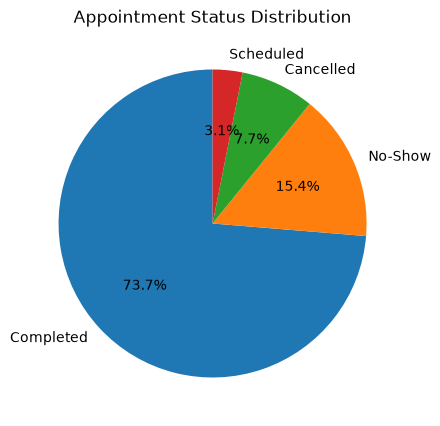

In [2]:
# Appointment status distribution
status_counts = appointments["appointment_status"].value_counts()

plt.figure(figsize=(8, 5))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Appointment Status Distribution")
plt.show()

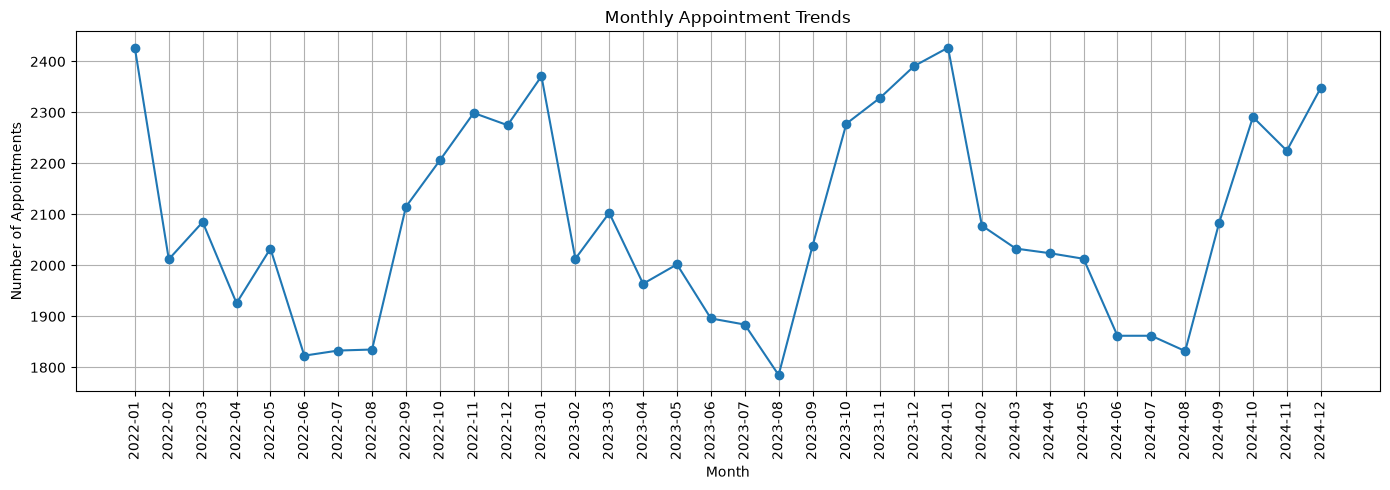

In [3]:
# Monthly appointment trends
monthly_appointments = (
    appointments
    .groupby(appointments["appointment_date"].dt.to_period("M"))
    .size()
)

plt.figure(figsize=(14, 5))
monthly_appointments.index = monthly_appointments.index.astype(str)

plt.plot(monthly_appointments.index, monthly_appointments.values, marker="o")

plt.title("Monthly Appointment Trends")
plt.xlabel("Month")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

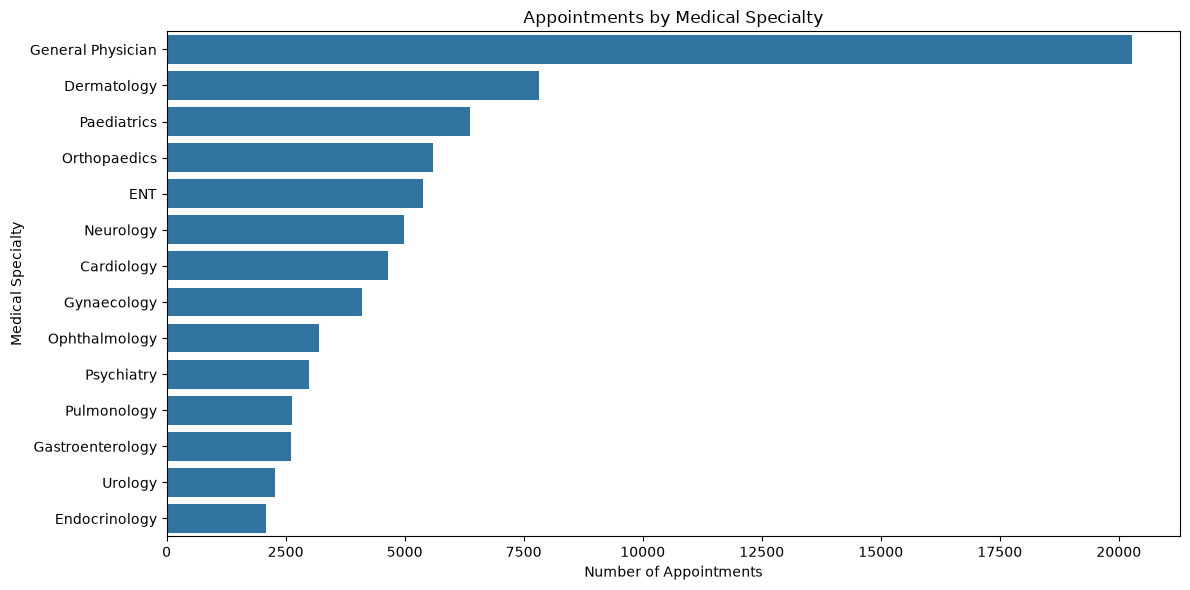

In [4]:
# Specialty-wise appointment analysis
specialty_counts = (
    appointments["specialty"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=specialty_counts.values,
    y=specialty_counts.index
)

plt.title("Appointments by Medical Specialty")
plt.xlabel("Number of Appointments")
plt.ylabel("Medical Specialty")
plt.tight_layout()
plt.show()

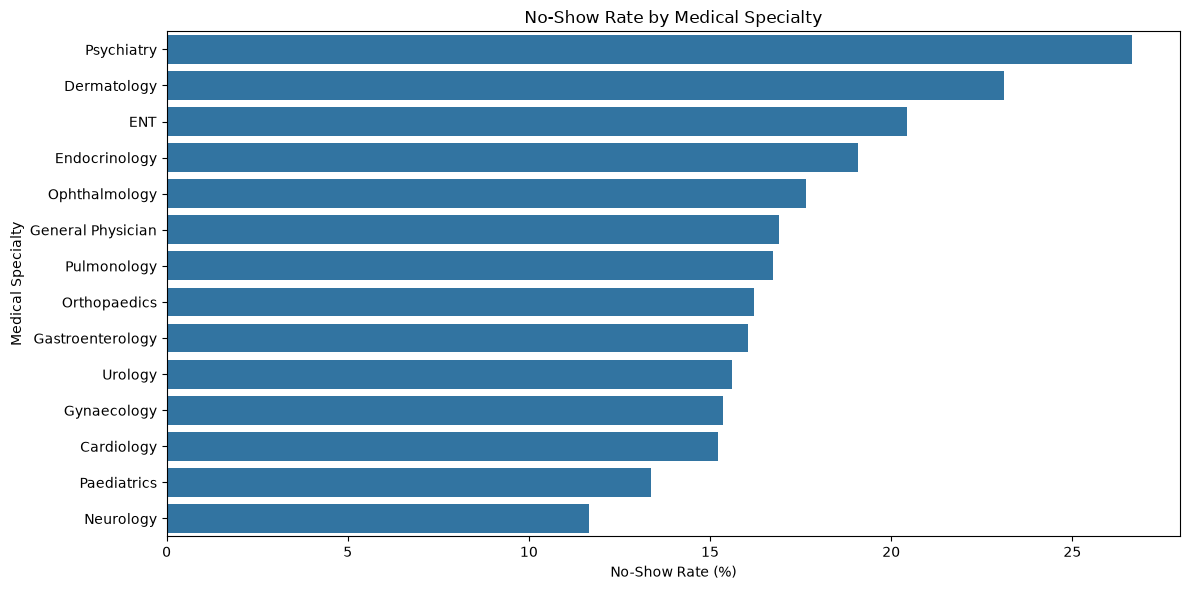

,total_appointments,no_shows,no_show_rate
specialty,,,
Psychiatry,2669,711,26.64
Dermatology,6955,1608,23.12
ENT,4833,988,20.44
Endocrinology,1859,355,19.10
Ophthalmology,2852,503,17.64
General Physician,18030,3049,16.91
Pulmonology,2355,394,16.73
Orthopaedics,4999,810,16.20
Gastroenterology,2349,377,16.05


In [5]:
# No-show rate by specialty
resolved_appointments = appointments[
    appointments["appointment_status"].isin(["Completed", "No-Show"])
]

no_show_analysis = (
    resolved_appointments
    .groupby("specialty")
    .agg(
        total_appointments=("appointment_id", "count"),
        no_shows=("no_show_flag", "sum")
    )
)

no_show_analysis["no_show_rate"] = (
    no_show_analysis["no_shows"] /
    no_show_analysis["total_appointments"] * 100
)

no_show_analysis = no_show_analysis.sort_values(
    "no_show_rate", ascending=False
)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=no_show_analysis["no_show_rate"],
    y=no_show_analysis.index
)

plt.title("No-Show Rate by Medical Specialty")
plt.xlabel("No-Show Rate (%)")
plt.ylabel("Medical Specialty")
plt.tight_layout()
plt.show()

display(no_show_analysis.round(2))

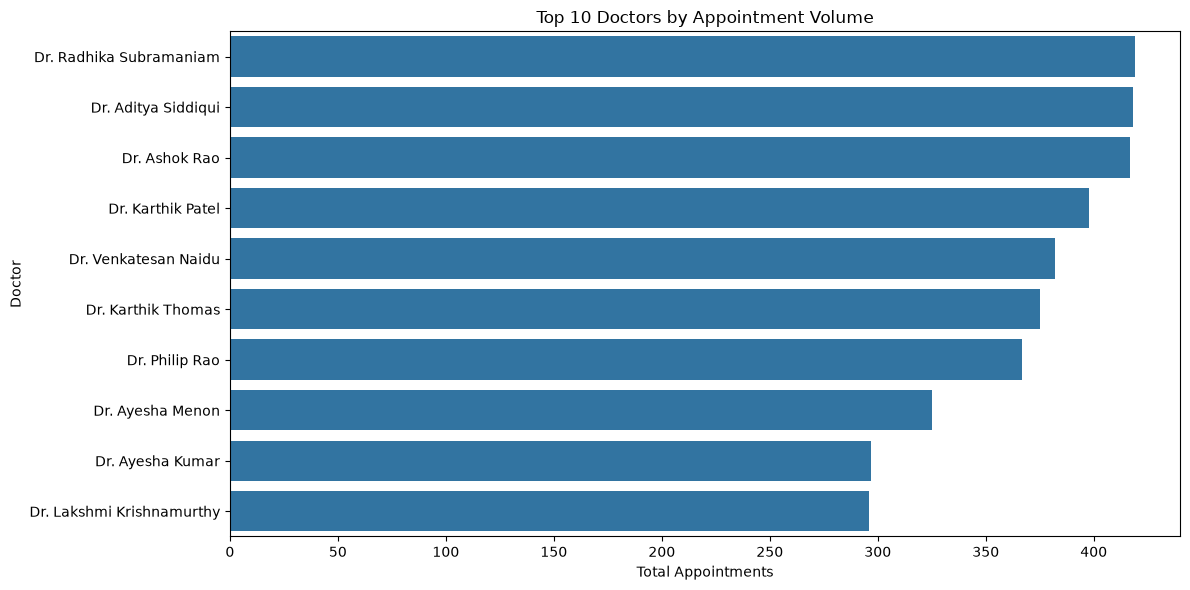

,doctor_id,total_appointments,completed_appointments,avg_utilization,doctor_name,specialty
246,DOC1247,419,305,76.59,Dr. Radhika Subramaniam,General Physician
257,DOC1258,418,315,76.41,Dr. Aditya Siddiqui,General Physician
239,DOC1240,417,307,77.63,Dr. Ashok Rao,General Physician
29,DOC1030,398,268,77.08,Dr. Karthik Patel,Dermatology
181,DOC1182,382,304,76.54,Dr. Venkatesan Naidu,Cardiology
111,DOC1112,375,270,75.01,Dr. Karthik Thomas,Ophthalmology
258,DOC1259,367,261,75.33,Dr. Philip Rao,General Physician
251,DOC1252,325,235,76.14,Dr. Ayesha Menon,Paediatrics
144,DOC1145,297,241,75.93,Dr. Ayesha Kumar,Paediatrics
10,DOC1011,296,211,76.78,Dr. Lakshmi Krishnamurthy,Endocrinology


In [6]:
# Doctor workload analysis
doctor_workload = (
    appointments
    .groupby("doctor_id")
    .agg(
        total_appointments=("appointment_id", "count"),
        completed_appointments=(
            "appointment_status",
            lambda x: (x == "Completed").sum()
        ),
        avg_utilization=("doctor_utilization_pct", "mean")
    )
    .reset_index()
)

# Add doctor names and specialties
doctor_workload = doctor_workload.merge(
    doctors[["doctor_id", "doctor_name", "specialty"]],
    on="doctor_id",
    how="left"
)

# Select top 10 busiest doctors
top_doctors = doctor_workload.sort_values(
    "total_appointments",
    ascending=False
).head(10)

# Visualisation
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_doctors,
    x="total_appointments",
    y="doctor_name"
)

plt.title("Top 10 Doctors by Appointment Volume")
plt.xlabel("Total Appointments")
plt.ylabel("Doctor")
plt.tight_layout()
plt.show()

display(top_doctors.round(2))

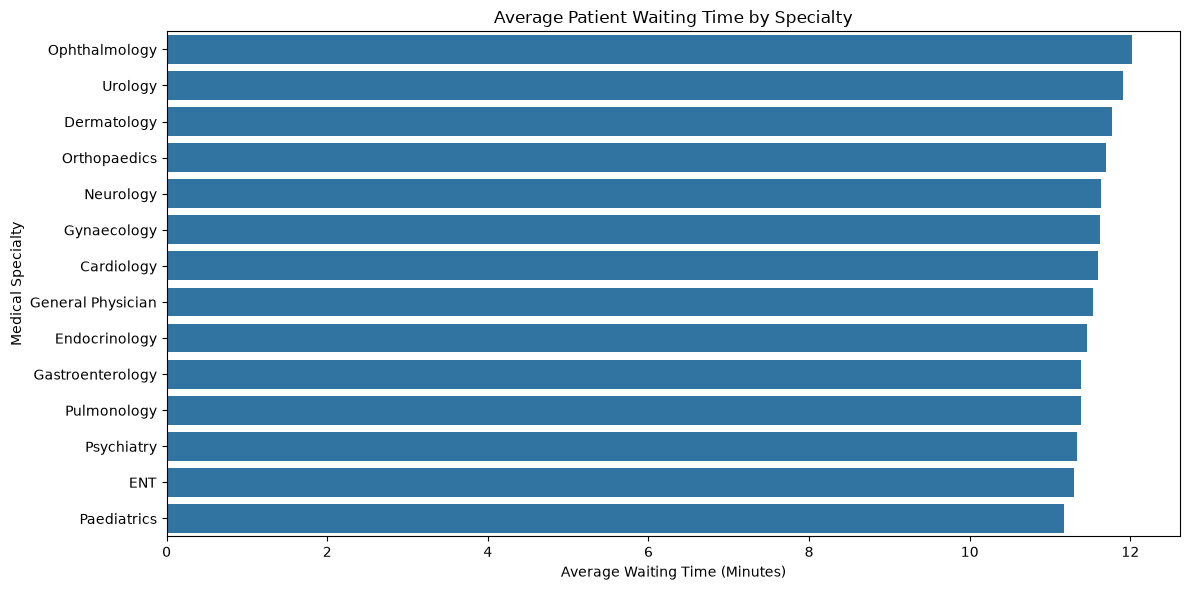

,total_visits,avg_waiting_time,max_waiting_time
specialty,,,
Ophthalmology,2349,12.02,90.0
Urology,1729,11.91,90.0
Dermatology,5347,11.77,90.0
Orthopaedics,4189,11.70,90.0
Neurology,3899,11.64,90.0
Gynaecology,3134,11.62,84.0
Cardiology,3507,11.59,90.0
General Physician,14981,11.53,90.0
Endocrinology,1504,11.46,88.0


In [7]:
# Patient waiting time analysis
waiting_analysis = (
    appointments[appointments["appointment_status"] == "Completed"]
    .groupby("specialty")
    .agg(
        total_visits=("appointment_id", "count"),
        avg_waiting_time=("wait_time_minutes", "mean"),
        max_waiting_time=("wait_time_minutes", "max")
    )
    .sort_values("avg_waiting_time", ascending=False)
)

# Visualisation
plt.figure(figsize=(12, 6))

sns.barplot(
    x=waiting_analysis["avg_waiting_time"],
    y=waiting_analysis.index
)

plt.title("Average Patient Waiting Time by Specialty")
plt.xlabel("Average Waiting Time (Minutes)")
plt.ylabel("Medical Specialty")
plt.tight_layout()
plt.show()

display(waiting_analysis.round(2))

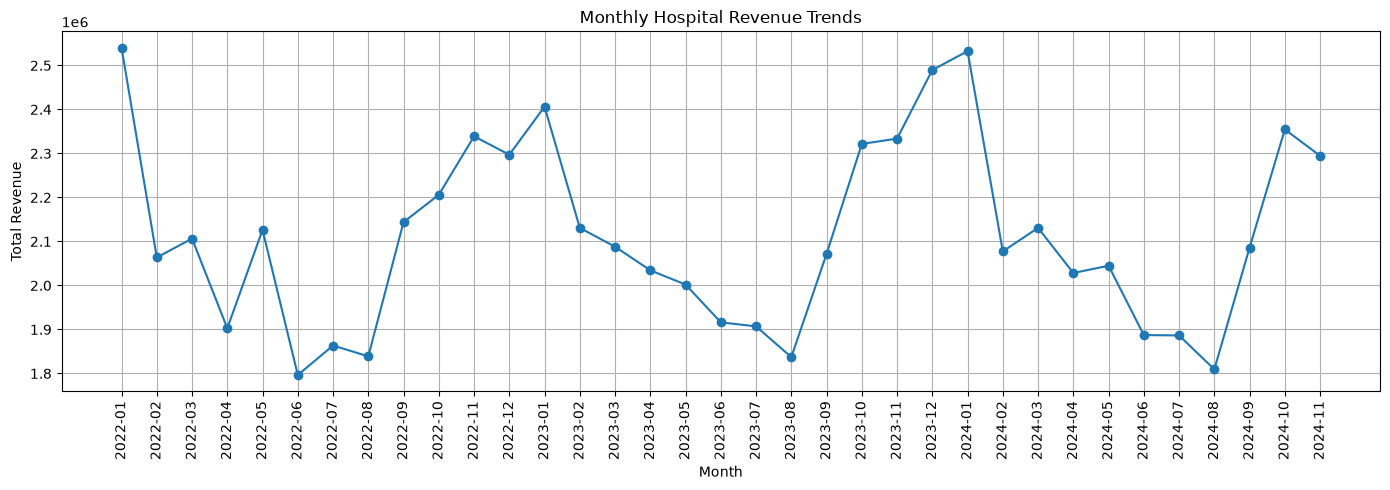

,appointment_date,total_revenue,total_visits
0,2022-01,2540245,1860
1,2022-02,2063595,1535
2,2022-03,2106429,1572
3,2022-04,1902614,1459
4,2022-05,2126228,1569
5,2022-06,1796465,1370
6,2022-07,1863465,1379
7,2022-08,1838905,1409
8,2022-09,2143922,1619
9,2022-10,2205946,1680


In [8]:
# Monthly revenue analysis
completed = appointments[
    appointments["appointment_status"] == "Completed"
].copy()

monthly_revenue = (
    completed
    .groupby(completed["appointment_date"].dt.to_period("M"))
    .agg(
        total_revenue=("revenue_realized", "sum"),
        total_visits=("appointment_id", "count")
    )
    .reset_index()
)

monthly_revenue["appointment_date"] = (
    monthly_revenue["appointment_date"].astype(str)
)

# Visualisation
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_revenue["appointment_date"],
    monthly_revenue["total_revenue"],
    marker="o"
)

plt.title("Monthly Hospital Revenue Trends")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

display(monthly_revenue.round(2))

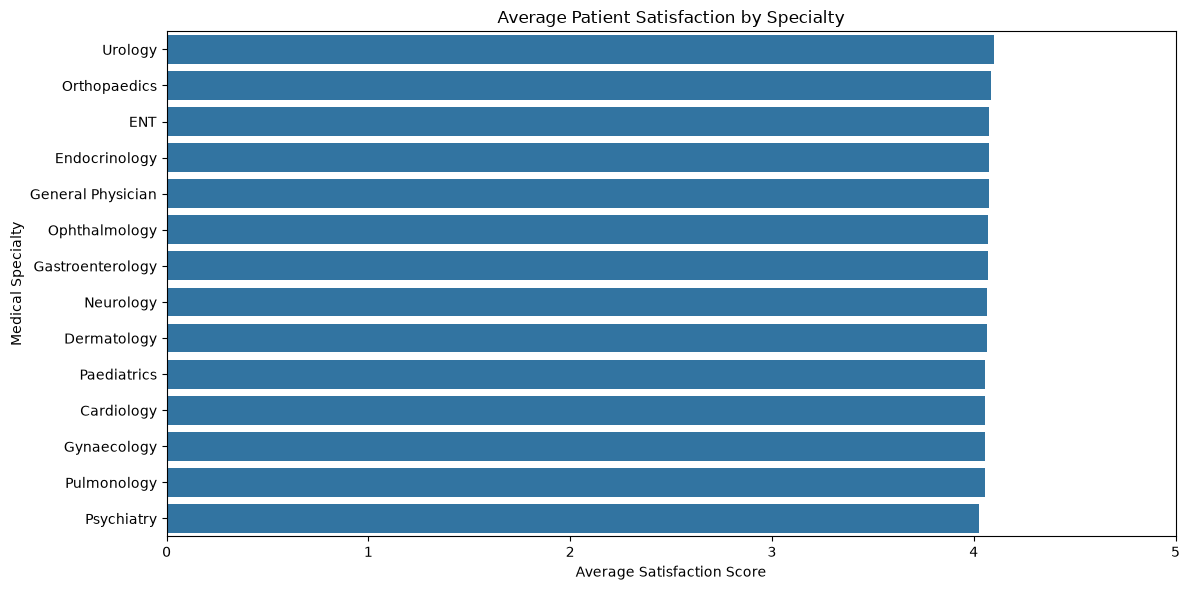

,total_feedback,avg_satisfaction
specialty,,
Urology,1729,4.10
Orthopaedics,4189,4.08
ENT,3845,4.08
Endocrinology,1504,4.08
General Physician,14981,4.07
Ophthalmology,2349,4.07
Gastroenterology,1972,4.07
Neurology,3899,4.07
Dermatology,5347,4.06


In [9]:
# Patient satisfaction analysis
satisfaction_analysis = (
    appointments[
        (appointments["appointment_status"] == "Completed") &
        (appointments["patient_satisfaction_score"].notna())
    ]
    .groupby("specialty")
    .agg(
        total_feedback=("patient_satisfaction_score", "count"),
        avg_satisfaction=("patient_satisfaction_score", "mean")
    )
    .sort_values("avg_satisfaction", ascending=False)
)

# Visualisation
plt.figure(figsize=(12, 6))

sns.barplot(
    x=satisfaction_analysis["avg_satisfaction"],
    y=satisfaction_analysis.index
)

plt.title("Average Patient Satisfaction by Specialty")
plt.xlabel("Average Satisfaction Score")
plt.ylabel("Medical Specialty")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

display(satisfaction_analysis.round(2))